<a href="https://colab.research.google.com/github/dev-abraao/IAmarcos/blob/main/segmentacao_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import importlib.util
import subprocess
import sys

FIXAR_VERSOES = False
DEPENDENCIAS = {
    "numpy": "numpy==2.2.6",
    "pandas": "pandas==2.2.3",
    "scipy": "scipy==1.15.3",
    "sklearn": "scikit-learn==1.6.1",
    "matplotlib": "matplotlib==3.10.3",
    "seaborn": "seaborn==0.13.2",
    "openpyxl": "openpyxl==3.1.5",
    "joblib": "joblib==1.5.1",
    "threadpoolctl": "threadpoolctl==3.6.0",
}
instalar = [pacote for modulo, pacote in DEPENDENCIAS.items()
            if FIXAR_VERSOES or importlib.util.find_spec(modulo) is None]
if instalar:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *instalar])


import hashlib
import json
import platform
import shutil
import unicodedata
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score,
    davies_bouldin_score, silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

SEMENTE = 42
K_TESTADOS = tuple(range(2, 7))
N_INIT_KMEANS = 30
MIN_SAMPLES_DBSCAN = (3, 5, 8)
QUANTIS_EPS = (0.50, 0.65, 0.80, 0.90, 0.95)
MULTIPLICADORES_EPS = (0.8, 1.0, 1.2)
MIN_TAMANHO_GRUPO = 5
MIN_COBERTURA = 0.80
REPETICOES_ESTABILIDADE = 30
FRACAO_SUBAMOSTRA = 0.80
CATEGORIAS = ["hortifruti", "carnes", "laticinios"]
NOMES_CATEGORIAS = ["Hortifruti", "Carnes", "Laticínios"]
COLUNAS_PARCELAS = [f"parcela_{c}" for c in CATEGORIAS]
REPRESENTACOES = ("absolutos", "participacoes")
ALGORITMOS = ("K-Means", "Hierarquico", "DBSCAN")


REFERENCIA_COMERCIAL = ("participacoes", "K-Means")
ARQUIVO_DADOS = None
BAIXAR_ZIP_NO_COLAB = False

EXECUCAO = datetime.now(timezone.utc).strftime("execucao_%Y%m%dT%H%M%S_%fZ")
SAIDA = Path("resultados") / EXECUCAO
for subpasta in ("tabelas", "figuras", "modelos"):
    (SAIDA / subpasta).mkdir(parents=True, exist_ok=True)

def salvar_tabela(tabela, nome):
    tabela.to_csv(SAIDA / "tabelas" / f"{nome}.csv", index=False, encoding="utf-8-sig")

def salvar_figura(figura, nome):
    for extensao in ("png", "pdf"):
        figura.savefig(SAIDA / "figuras" / f"{nome}.{extensao}", bbox_inches="tight")



def localizar_dados(caminho=None):
    if caminho is not None:
        arquivo = Path(caminho).expanduser()
        if not arquivo.is_file():
            raise FileNotFoundError(f"Arquivo configurado não encontrado: {arquivo}")
        return arquivo
    candidatos = [Path("dados/p45b.xlsx"), Path("p45b.xlsx"),
                  Path("../dados/p45b.xlsx"), Path("/content/p45b.xlsx")]
    for candidato in candidatos:
        if candidato.is_file():
            return candidato
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Coloque p45b.xlsx em dados/ ou defina ARQUIVO_DADOS."
        ) from exc
    print("Envie o arquivo p45b.xlsx:")
    enviados = files.upload()
    if "p45b.xlsx" not in enviados:
        raise FileNotFoundError("O arquivo enviado deve se chamar p45b.xlsx.")
    return Path("p45b.xlsx")

def normalizar_nome(texto):
    texto = unicodedata.normalize("NFKD", str(texto).strip().lower())
    return "".join(c for c in texto if not unicodedata.combining(c))

def validar_base(original):
    dados = original.copy()
    dados.columns = [normalizar_nome(c) for c in dados.columns]
    esperadas = ["cliente", *CATEGORIAS, "canal", "pedidos", "sexo"]
    if dados.columns.duplicated().any() or set(dados.columns) != set(esperadas):
        raise ValueError(f"Colunas esperadas: {esperadas}; recebidas: {list(dados.columns)}")
    dados = dados[esperadas]
    if dados.empty or dados.isna().any().any():
        raise ValueError("A base está vazia ou contém valores ausentes.")
    if dados["cliente"].duplicated().any():
        raise ValueError("Há identificadores de cliente repetidos.")
    for categoria in CATEGORIAS:
        dados[categoria] = pd.to_numeric(dados[categoria], errors="raise")
    valores = dados[CATEGORIAS].to_numpy(dtype=float)
    if not np.isfinite(valores).all() or (valores < 0).any():
        raise ValueError("Gastos devem ser finitos e não negativos.")
    permitidos = {"canal": {"net", "fone"},
                  "pedidos": {"10menos", "11a20", "21mais"},
                  "sexo": {"fem", "masc"}}
    for coluna, dominio in permitidos.items():
        dados[coluna] = dados[coluna].astype(str).str.strip().str.lower()
        inesperados = set(dados[coluna]) - dominio
        if inesperados:
            raise ValueError(f"Categorias inesperadas em {coluna}: {inesperados}")
    dados["gasto_total"] = dados[CATEGORIAS].sum(axis=1)
    if (dados["gasto_total"] <= 0).any():
        raise ValueError("Cada cliente precisa ter gasto total positivo.")
    dados[COLUNAS_PARCELAS] = dados[CATEGORIAS].div(dados["gasto_total"], axis=0).to_numpy()
    if not np.allclose(dados[COLUNAS_PARCELAS].sum(axis=1), 1.0):
        raise ValueError("As participações não somam 1.")
    return dados.reset_index(drop=True)

caminho_dados = localizar_dados(ARQUIVO_DADOS)
sha256_dados = hashlib.sha256(caminho_dados.read_bytes()).hexdigest()
df = validar_base(pd.read_excel(caminho_dados, sheet_name=0, engine="openpyxl"))
if len(df) < max(K_TESTADOS) * MIN_TAMANHO_GRUPO:
    raise ValueError("Base pequena demais para os limites deste protocolo.")

Envie o arquivo p45b.xlsx:


Saving p45b.xlsx to p45b.xlsx


## 1. Análise exploratória e valores atípicos

O gasto total serve para descrever os grupos e construir as participações;
não é adicionado aos gastos absolutos como uma quarta variável redundante.
A regra de 1,5 intervalo interquartil sinaliza casos incomuns. Eles permanecem
na análise principal e são retirados somente na análise de sensibilidade.

,variavel,count,mean,std,min,25%,50%,75%,max
0,hortifruti,81.0000,419.4444,200.4032,130.0000,241.0000,396.0000,552.0000,996.0000
1,carnes,81.0000,166.7037,63.1994,56.0000,120.0000,148.0000,214.0000,374.0000
2,laticinios,81.0000,127.7160,47.9360,41.0000,92.0000,128.0000,156.0000,245.0000
3,gasto_total,81.0000,713.8642,154.9802,442.0000,618.0000,690.0000,799.0000,1241.0000


,categoria,n,variavel,percentual
0,net,50,canal,61.7284
1,fone,31,canal,38.2716
2,11a20,43,pedidos,53.0864
3,10menos,23,pedidos,28.3951
4,21mais,15,pedidos,18.5185
5,masc,44,sexo,54.3210
6,fem,37,sexo,45.6790


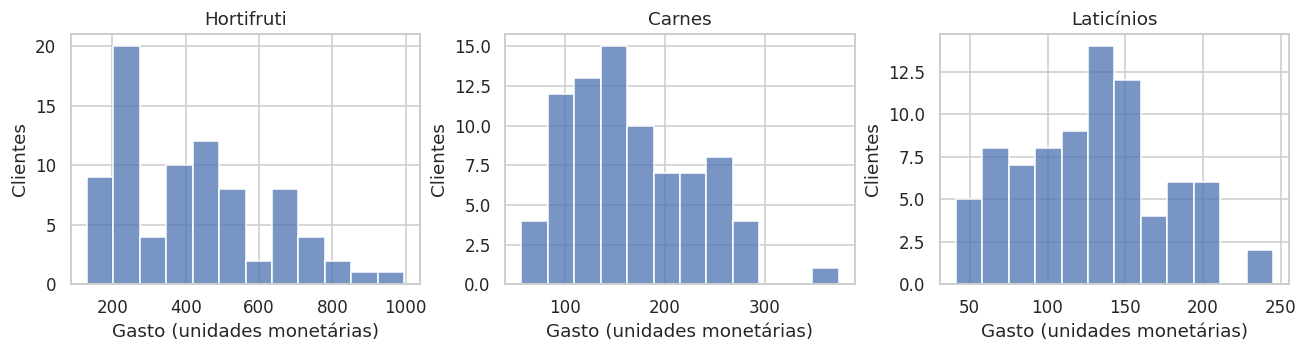

Casos sinalizados pelo IQR: 4; todos mantidos na análise principal.


In [ ]:
descritivas = df[CATEGORIAS + ["gasto_total"]].describe().T.reset_index(names="variavel")
salvar_tabela(descritivas, "estatisticas_descritivas")
display(descritivas)

distribuicoes = pd.concat([
    df[coluna].value_counts().rename_axis("categoria").reset_index(name="n").assign(variavel=coluna)
    for coluna in ("canal", "pedidos", "sexo")
], ignore_index=True)
distribuicoes["percentual"] = 100 * distribuicoes["n"] / len(df)
salvar_tabela(distribuicoes, "distribuicoes_cadastrais")
display(distribuicoes)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, categoria, nome in zip(axes, CATEGORIAS, NOMES_CATEGORIAS):
    sns.histplot(data=df, x=categoria, bins=12, ax=ax)
    ax.set(xlabel="Gasto (unidades monetárias)", ylabel="Clientes", title=nome)
fig.tight_layout()
salvar_figura(fig, "distribuicoes_gastos")
plt.show()

valores_iqr = df[CATEGORIAS + ["gasto_total"]]
q1, q3 = valores_iqr.quantile(0.25), valores_iqr.quantile(0.75)
iqr = q3 - q1
mascara_atipicos = ((valores_iqr < q1 - 1.5 * iqr) |
                    (valores_iqr > q3 + 1.5 * iqr)).any(axis=1).to_numpy()
limites_iqr = pd.DataFrame({"q1": q1, "q3": q3,
                           "limite_inferior": q1 - 1.5 * iqr,
                           "limite_superior": q3 + 1.5 * iqr}).reset_index(names="variavel")
salvar_tabela(limites_iqr, "limites_iqr")
salvar_tabela(df.loc[mascara_atipicos, ["cliente", *CATEGORIAS, "gasto_total"]], "casos_atipicos_iqr")
print(f"Casos sinalizados pelo IQR: {mascara_atipicos.sum()}; todos mantidos na análise principal.")

## 2. Representações e implementação dos modelos

**K-Means:** minimiza a soma das distâncias quadráticas aos centros, com
inicialização `k-means++`, 30 inicializações e semente fixa.

**Hierárquico:** começa com clientes separados e une grupos pelo critério
Ward, que usa distância euclidiana e minimiza o aumento de variância interna.

**DBSCAN:** forma grupos por densidade com `eps` e `min_samples`. O rótulo
`-1` representa ruído. Não deve ser apresentado como segmento comercial.

A seleção usa as três dimensões de cada representação. PCA é usada somente
nos gráficos, e não para ajustar ou escolher os agrupamentos.

São usados somente os gastos para formar os grupos; canal e faixa de pedidos descrevem os perfis posteriormente. Gastos absolutos são padronizados; participações são frações do gasto total, sem padronização adicional, e somam 1 por construção.

In [ ]:
def transformar(dados, representacao):
    if representacao == "absolutos":
        transformador = StandardScaler()
        X = transformador.fit_transform(dados[CATEGORIAS])
    elif representacao == "participacoes":
        transformador = None
        X = dados[COLUNAS_PARCELAS].to_numpy(dtype=float)
    else:
        raise ValueError("Representação desconhecida.")
    return np.asarray(X), transformador

def construir_modelo(algoritmo, parametros, semente=SEMENTE):
    if algoritmo == "K-Means":
        return KMeans(n_clusters=parametros["k"], n_init=N_INIT_KMEANS,
                      init="k-means++", random_state=semente)
    if algoritmo == "Hierarquico":
        return AgglomerativeClustering(n_clusters=parametros["k"], linkage="ward")
    if algoritmo == "DBSCAN":
        return DBSCAN(eps=parametros["eps"], min_samples=parametros["min_samples"],
                      metric="euclidean", n_jobs=1)
    raise ValueError("Algoritmo desconhecido.")

def ajustar(X, algoritmo, parametros, semente=SEMENTE):
    modelo = construir_modelo(algoritmo, parametros, semente)
    # Evita excesso de threads para uma amostra pequena e facilita a réplica.
    with threadpool_limits(limits=1):
        labels = modelo.fit_predict(X)
    return modelo, labels

def avaliar_particao(X, labels):
    labels = np.asarray(labels)
    agrupados = labels >= 0
    tamanhos = pd.Series(labels[agrupados]).value_counts()
    n_grupos = len(tamanhos)
    cobertura = float(agrupados.mean())
    silhueta = db = ch = np.nan
    if 2 <= n_grupos < int(agrupados.sum()):
        silhueta = float(silhouette_score(X[agrupados], labels[agrupados]))
        db = float(davies_bouldin_score(X[agrupados], labels[agrupados]))
        ch = float(calinski_harabasz_score(X[agrupados], labels[agrupados]))
    menor = int(tamanhos.min()) if n_grupos else 0
    motivos = []
    if n_grupos < 2:
        motivos.append("menos de dois grupos")
    if menor < MIN_TAMANHO_GRUPO:
        motivos.append("grupo menor que o limite")
    if cobertura < MIN_COBERTURA:
        motivos.append("cobertura insuficiente")
    if not np.isfinite(silhueta):
        motivos.append("silhueta indefinida")
    return {"n_grupos": n_grupos, "n_ruido": int((~agrupados).sum()),
            "cobertura": cobertura, "menor_grupo": menor,
            "silhueta": silhueta, "davies_bouldin": db, "calinski_harabasz": ch,
            "criterio_selecao": cobertura * silhueta - (1 - cobertura),
            "elegivel": not motivos, "motivo": "; ".join(motivos)}

espacos = {rep: transformar(df, rep) for rep in REPRESENTACOES}

## 3. Busca de parâmetros e comparação dos modelos

Para cada `min_samples`, calculamos a distância ao vizinho nessa posição
(incluindo o próprio cliente, como no critério do DBSCAN). Os quantis dessas
distâncias, multiplicados por 0,8, 1 e 1,2, geram os candidatos de `eps`.
Configurações sem dois grupos ou com muitos casos isolados continuam nas
tabelas, mas não são selecionadas. Não forçamos um resultado para o DBSCAN.

Testamos de 2 a 6 grupos no K-Means e no hierárquico. A seleção exige pelo menos dois grupos, cinco clientes em cada grupo e cobertura mínima de 80%. Por algoritmo e representação, maximizamos a heurística `cobertura × silhueta − (1 − cobertura)`, com desempate por silhueta, Davies–Bouldin e menor número de grupos. Não há vencedor global automático. As métricas do DBSCAN excluem ruído e são acompanhadas da cobertura; são avaliações internas exploratórias.

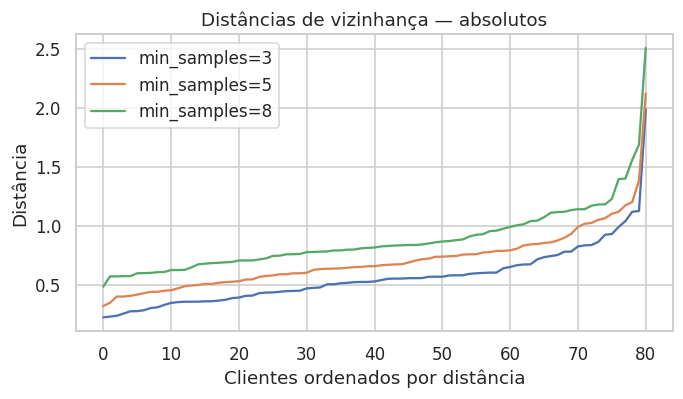

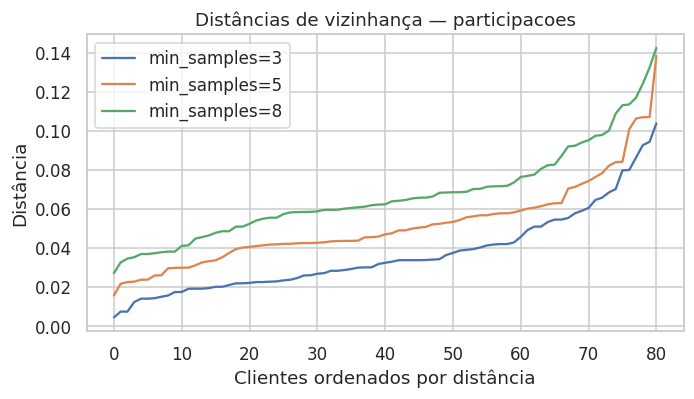

,id,representacao,algoritmo,parametros,n_grupos,n_ruido,cobertura,menor_grupo,silhueta,davies_bouldin,calinski_harabasz,criterio_selecao,elegivel
0,config_015,absolutos,DBSCAN,"{""eps"": 0.6358384737654358, ""min_samples"": 3}",3,14,0.8272,6,0.2447,1.2775,48.8150,0.0295,True
1,config_005,absolutos,Hierarquico,"{""k"": 2}",2,0,1.0000,26,0.4078,0.8374,71.7614,0.4078,True
2,config_000,absolutos,K-Means,"{""k"": 2}",2,0,1.0000,34,0.4398,0.8501,89.0723,0.4398,True
3,config_102,participacoes,DBSCAN,"{""eps"": 0.08243308765059705, ""min_samples"": 8}",2,2,0.9753,28,0.5990,0.5062,197.8613,0.5595,True
4,config_060,participacoes,Hierarquico,"{""k"": 2}",2,0,1.0000,30,0.5938,0.5231,200.0338,0.5938,True
5,config_055,participacoes,K-Means,"{""k"": 2}",2,0,1.0000,35,0.6111,0.5211,232.2037,0.6111,True


In [ ]:
registros, ajustes, parametros_por_id = [], {}, {}
id_config = 0
for representacao, (X, transformador) in espacos.items():
    configuracoes = [(alg, {"k": k})
                     for alg in ("K-Means", "Hierarquico") for k in K_TESTADOS]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for min_samples in MIN_SAMPLES_DBSCAN:
        distancias, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
        distancias_k = distancias[:, -1]
        ax.plot(np.sort(distancias_k), label=f"min_samples={min_samples}")
        eps_candidatos = sorted({
            float(np.quantile(distancias_k, q) * multiplicador)
            for q in QUANTIS_EPS for multiplicador in MULTIPLICADORES_EPS
            if np.quantile(distancias_k, q) * multiplicador > 0
        })
        configuracoes.extend(("DBSCAN", {"eps": eps, "min_samples": min_samples})
                             for eps in eps_candidatos)
    ax.set(title=f"Distâncias de vizinhança — {representacao}",
           xlabel="Clientes ordenados por distância", ylabel="Distância")
    ax.legend()
    salvar_figura(fig, f"vizinhos_dbscan_{representacao}")
    plt.show()

    for algoritmo, parametros in configuracoes:
        modelo, labels = ajustar(X, algoritmo, parametros)
        identificador = f"config_{id_config:03d}"
        id_config += 1
        metricas = avaliar_particao(X, labels)
        registros.append({"id": identificador, "representacao": representacao,
                          "algoritmo": algoritmo,
                          "parametros": json.dumps(parametros, sort_keys=True), **metricas})
        ajustes[identificador] = (modelo, labels)
        parametros_por_id[identificador] = parametros

resultados = pd.DataFrame(registros)
salvar_tabela(resultados, "todas_configuracoes")
elegiveis = resultados.loc[resultados["elegivel"]].sort_values(
    ["criterio_selecao", "silhueta", "davies_bouldin", "n_grupos"],
    ascending=[False, False, True, True], kind="mergesort")
melhores = elegiveis.groupby(["representacao", "algoritmo"], sort=False).head(1).copy()
melhores = melhores.sort_values(["representacao", "algoritmo"]).reset_index(drop=True)
salvar_tabela(melhores, "melhores_por_algoritmo")
display(melhores.drop(columns=["motivo"]))
pares_encontrados = set(zip(melhores["representacao"], melhores["algoritmo"]))
for rep in REPRESENTACOES:
    for alg in ALGORITMOS:
        if (rep, alg) not in pares_encontrados:
            print(f"Sem configuração elegível: {rep} / {alg}.")

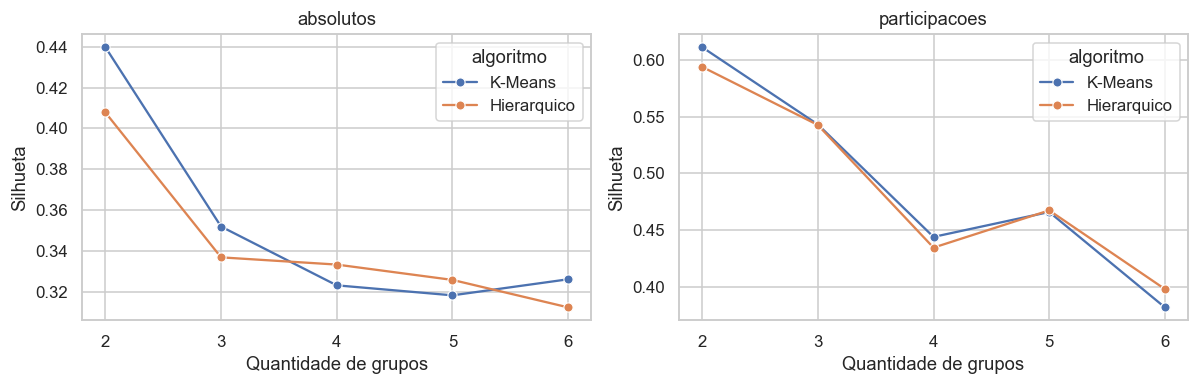

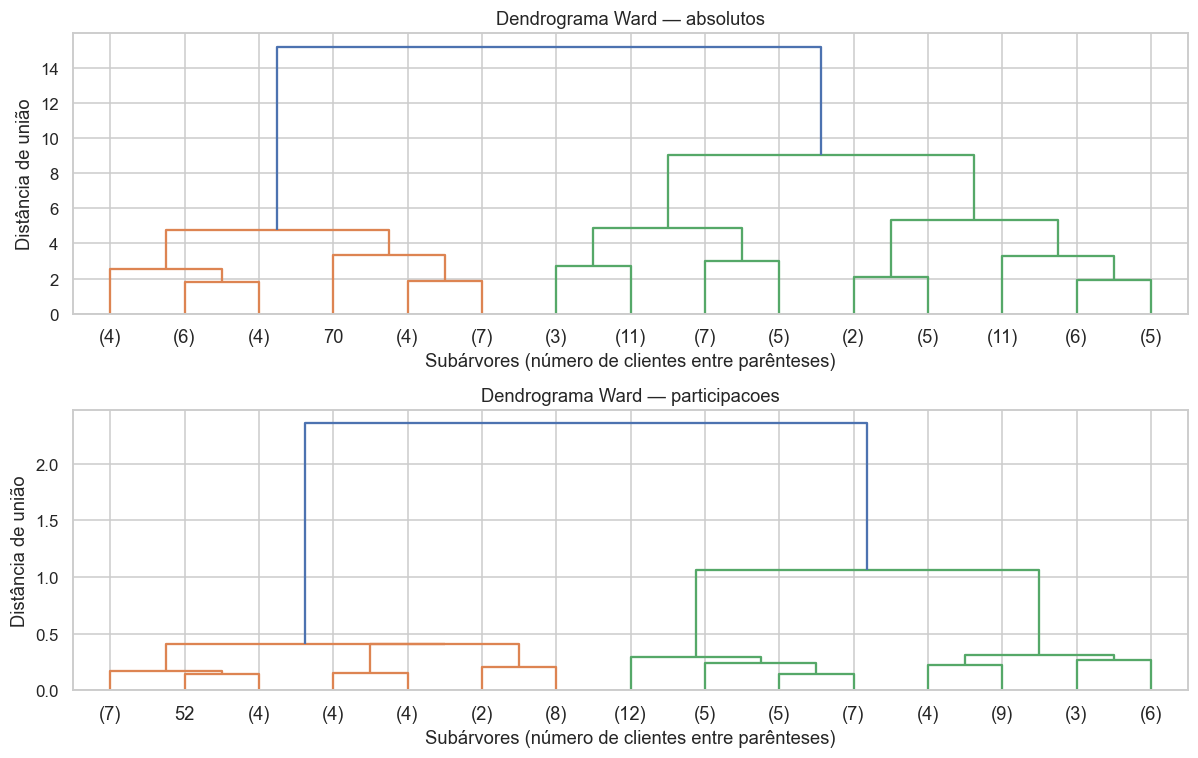

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, rep in zip(axes, REPRESENTACOES):
    dados_k = resultados[(resultados["representacao"] == rep) &
                         resultados["algoritmo"].isin(["K-Means", "Hierarquico"])].copy()
    dados_k["k"] = dados_k["parametros"].map(lambda p: json.loads(p)["k"])
    sns.lineplot(data=dados_k, x="k", y="silhueta", hue="algoritmo", marker="o", ax=ax)
    ax.set(title=rep, xlabel="Quantidade de grupos", ylabel="Silhueta")
    ax.set_xticks(K_TESTADOS)
fig.tight_layout()
salvar_figura(fig, "silhueta_por_k")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, rep in zip(axes, REPRESENTACOES):
    dendrogram(linkage(espacos[rep][0], method="ward"),
               truncate_mode="lastp", p=15, show_leaf_counts=True, ax=ax)
    ax.set(title=f"Dendrograma Ward — {rep}",
           xlabel="Subárvores (número de clientes entre parênteses)", ylabel="Distância de união")
fig.tight_layout()
salvar_figura(fig, "dendrogramas_ward")
plt.show()

## 4. Estabilidade por subamostragem

Reajustamos cada configuração selecionada em 30 subamostras de 80% dos
clientes, usando os mesmos índices para todos os métodos. A padronização dos
gastos absolutos é reajustada em cada subamostra. O ARI compara os rótulos
originais restritos aos clientes amostrados com os novos rótulos.

Reportamos ARI de todos os clientes (ruído pode contar como um rótulo) e ARI
apenas dos clientes agrupados nas duas partições. Este segundo ARI só é
calculado se houver pelo menos dois grupos em cada partição no conjunto comum.
Cobertura comum e fração de repetições elegíveis evitam interpretar alto ARI
entre partições degeneradas como evidência de estabilidade útil.

In [ ]:
def comparar_rotulos(labels_a, labels_b):
    labels_a, labels_b = np.asarray(labels_a), np.asarray(labels_b)
    comuns = (labels_a >= 0) & (labels_b >= 0)
    ari_comuns = np.nan
    if (comuns.sum() >= 3 and len(np.unique(labels_a[comuns])) >= 2
            and len(np.unique(labels_b[comuns])) >= 2):
        ari_comuns = float(adjusted_rand_score(labels_a[comuns], labels_b[comuns]))
    return {"ari_todos": float(adjusted_rand_score(labels_a, labels_b)),
            "ari_agrupados": ari_comuns,
            "cobertura_comum": float(comuns.mean())}

rng = np.random.default_rng(SEMENTE)
n_subamostra = int(np.floor(FRACAO_SUBAMOSTRA * len(df)))
subamostras = [np.sort(rng.choice(len(df), n_subamostra, replace=False))
              for _ in range(REPETICOES_ESTABILIDADE)]
registros_estabilidade = []
for _, config in melhores.iterrows():
    rep, alg, identificador = config["representacao"], config["algoritmo"], config["id"]
    labels_base = ajustes[identificador][1]
    for repeticao, indices in enumerate(subamostras):
        X_sub, _ = transformar(df.iloc[indices], rep)
        _, labels_sub = ajustar(X_sub, alg, parametros_por_id[identificador],
                               semente=SEMENTE + repeticao + 1)
        metricas_sub = avaliar_particao(X_sub, labels_sub)
        registros_estabilidade.append({
            "id": identificador, "representacao": rep, "algoritmo": alg,
            "repeticao": repeticao + 1,
            **comparar_rotulos(labels_base[indices], labels_sub),
            "n_grupos_subamostra": metricas_sub["n_grupos"],
            "cobertura_subamostra": metricas_sub["cobertura"],
            "elegivel_subamostra": metricas_sub["elegivel"],
        })
estabilidade = pd.DataFrame(registros_estabilidade)
colunas_resumo_estabilidade = ["id", "representacao", "algoritmo", "ari_mediano",
                              "ari_q25", "ari_q75", "ari_agrupados_mediano",
                              "n_ari_agrupados_validos", "cobertura_comum_media",
                              "fracao_repeticoes_elegiveis"]
resumo_estabilidade = pd.DataFrame(columns=colunas_resumo_estabilidade)
if not estabilidade.empty:
    resumo_estabilidade = estabilidade.groupby(
        ["id", "representacao", "algoritmo"], as_index=False).agg(
        ari_mediano=("ari_todos", "median"),
        ari_q25=("ari_todos", lambda x: x.quantile(0.25)),
        ari_q75=("ari_todos", lambda x: x.quantile(0.75)),
        ari_agrupados_mediano=("ari_agrupados", "median"),
        n_ari_agrupados_validos=("ari_agrupados", "count"),
        cobertura_comum_media=("cobertura_comum", "mean"),
        fracao_repeticoes_elegiveis=("elegivel_subamostra", "mean"))
comparacao = melhores.merge(resumo_estabilidade, on=["id", "representacao", "algoritmo"], how="left")
salvar_tabela(estabilidade, "estabilidade_repeticoes")
salvar_tabela(comparacao, "comparacao_com_estabilidade")
display(comparacao[["representacao", "algoritmo", "n_grupos", "silhueta", "cobertura",
                    "ari_mediano", "ari_agrupados_mediano", "fracao_repeticoes_elegiveis"]])

,representacao,algoritmo,n_grupos,silhueta,cobertura,ari_mediano,ari_agrupados_mediano,fracao_repeticoes_elegiveis
0,absolutos,DBSCAN,3,0.2447,0.8272,0.6536,0.7509,0.0333
1,absolutos,Hierarquico,2,0.4078,1.0000,0.1775,0.1775,1.0000
2,absolutos,K-Means,2,0.4398,1.0000,1.0000,1.0000,1.0000
3,participacoes,DBSCAN,2,0.5990,0.9753,0.8963,1.0000,0.9667
4,participacoes,Hierarquico,2,0.5938,1.0000,0.9064,0.9064,1.0000
5,participacoes,K-Means,2,0.6111,1.0000,1.0000,1.0000,1.0000


## 5. Sensibilidade a valores atípicos e à representação

Retiramos temporariamente os casos sinalizados pelo IQR e reajustamos cada
configuração selecionada, com os mesmos parâmetros. Isso mede sensibilidade
condicional ao protocolo; não substitui a investigação da origem dos casos.
Também comparamos os resultados do mesmo algoritmo nas duas representações.
Elas respondem a perguntas diferentes e suas silhuetas não são uma competição
direta, pois usam geometrias distintas.

In [ ]:
registros_sensibilidade = []
indices_sem_atipicos = np.flatnonzero(~mascara_atipicos)
if mascara_atipicos.any() and len(indices_sem_atipicos) > max(K_TESTADOS):
    for _, config in melhores.iterrows():
        rep, alg, identificador = config["representacao"], config["algoritmo"], config["id"]
        X_sem, _ = transformar(df.iloc[indices_sem_atipicos], rep)
        _, labels_sem = ajustar(X_sem, alg, parametros_por_id[identificador])
        metricas_sem = avaliar_particao(X_sem, labels_sem)
        registros_sensibilidade.append({
            "representacao": rep, "algoritmo": alg,
            "n_clientes_sem_atipicos": len(indices_sem_atipicos),
            **comparar_rotulos(ajustes[identificador][1][indices_sem_atipicos], labels_sem),
            "n_grupos_sem_atipicos": metricas_sem["n_grupos"],
            "cobertura_sem_atipicos": metricas_sem["cobertura"],
            "elegivel_sem_atipicos": metricas_sem["elegivel"],
        })
sensibilidade = pd.DataFrame(registros_sensibilidade)
salvar_tabela(sensibilidade, "sensibilidade_atipicos")
display(sensibilidade)

comparacoes_representacoes = []
for alg in ALGORITMOS:
    configs = melhores[melhores["algoritmo"] == alg]
    if set(configs["representacao"]) == set(REPRESENTACOES):
        ids = configs.set_index("representacao")["id"]
        comparacoes_representacoes.append({"algoritmo": alg,
            **comparar_rotulos(ajustes[ids["absolutos"]][1], ajustes[ids["participacoes"]][1])})
comparacao_representacoes = pd.DataFrame(comparacoes_representacoes)
salvar_tabela(comparacao_representacoes, "concordancia_representacoes")
display(comparacao_representacoes)

,representacao,algoritmo,n_clientes_sem_atipicos,ari_todos,ari_agrupados,cobertura_comum,n_grupos_sem_atipicos,cobertura_sem_atipicos,elegivel_sem_atipicos
0,absolutos,DBSCAN,77,0.9738,1.0000,0.8442,3,0.8442,True
1,absolutos,Hierarquico,77,0.9475,0.9475,1.0000,2,1.0000,True
2,absolutos,K-Means,77,0.9481,0.9481,1.0000,2,1.0000,True
3,participacoes,DBSCAN,77,1.0000,1.0000,0.9870,2,0.9870,True
4,participacoes,Hierarquico,77,1.0000,1.0000,1.0000,2,1.0000,True
5,participacoes,K-Means,77,1.0000,1.0000,1.0000,2,1.0000,True


,algoritmo,ari_todos,ari_agrupados,cobertura_comum
0,K-Means,0.8555,0.8555,1.0000
1,Hierarquico,0.5589,0.5589,1.0000
2,DBSCAN,0.1533,0.2424,0.8148


## 6. Perfis dos segmentos e visualizações

Para cada configuração selecionada, exportamos os tamanhos dos grupos, médias
e medianas dos gastos, composição média e distribuição por canal e faixa de
pedidos. A média das participações individuais não é a participação na soma
de todos os gastos. Os números dos grupos são identificadores arbitrários.
Grupos de algoritmos diferentes podem ter o mesmo número sem representar
o mesmo perfil. Ruído permanece identificado separadamente.

Os gráficos PCA são projeções: pontos próximos ou separados no plano não
substituem as métricas calculadas no espaço original.

### absolutos — DBSCAN

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,-1,ruido,14,739.2857,57.3539,24.2634,18.3828
1,0,segmento,36,667.9167,45.5742,30.3762,24.0497
2,1,segmento,25,812.9600,75.1522,14.9333,9.9144
3,2,segmento,6,517.3333,41.7495,29.2310,29.0195


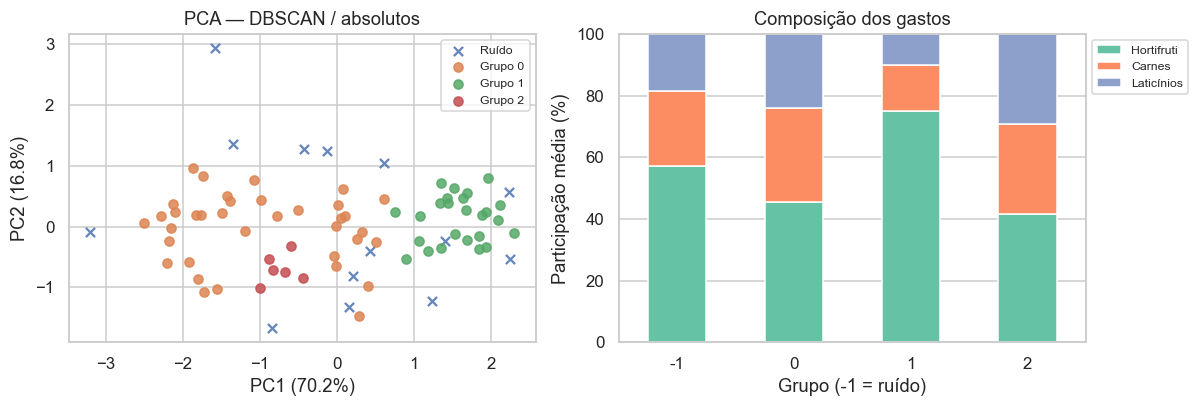

### absolutos — Hierarquico

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,0,segmento,55,738.8909,65.6005,18.9391,15.4604
1,1,segmento,26,660.9231,37.1116,36.1653,26.7231


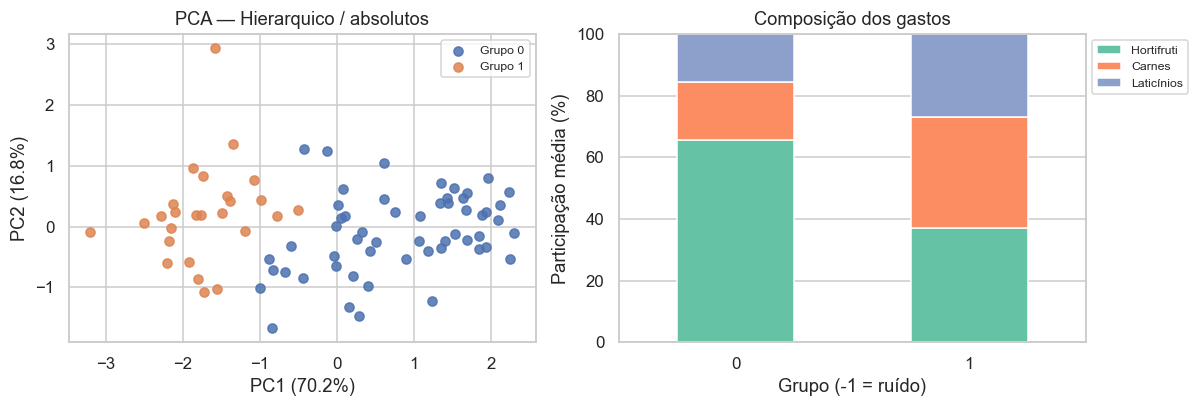

### absolutos — K-Means

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,0,segmento,34,634.6176,38.5113,34.3746,27.1141
1,1,segmento,47,771.1915,69.4371,17.3024,13.2605


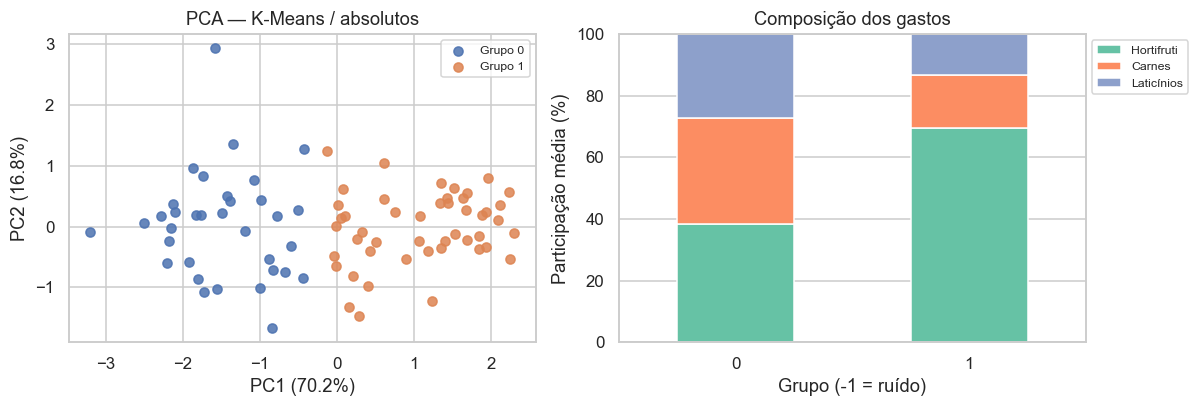

### participacoes — DBSCAN

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,-1,ruido,2,692.5000,36.2207,38.1720,25.6073
1,0,segmento,51,769.1176,68.0405,18.3025,13.6570
2,1,segmento,28,614.7500,36.8008,34.7205,28.4786


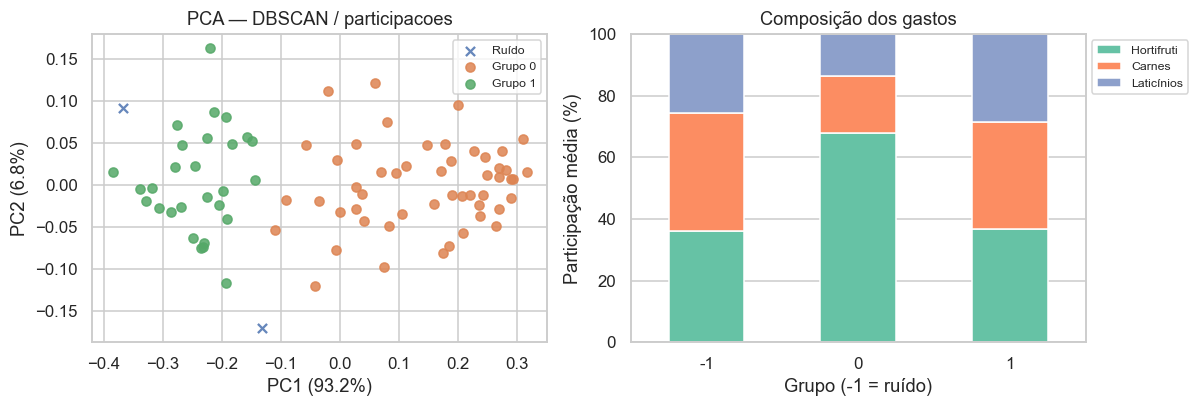

### participacoes — Hierarquico

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,0,segmento,51,769.1176,68.0405,18.3025,13.6570
1,1,segmento,30,619.9333,36.7621,34.9506,28.2872


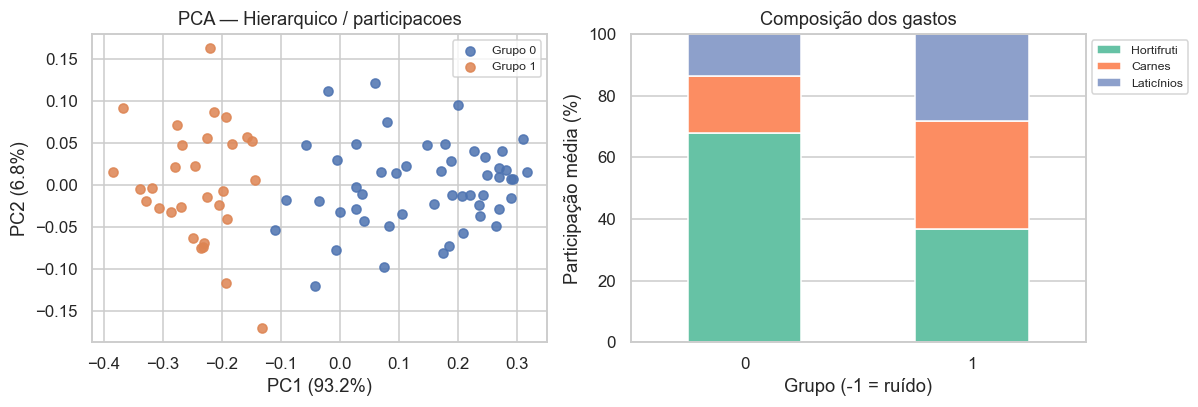

### participacoes — K-Means

,grupo,tipo,n,media_gasto_total,participacao_media_hortifruti_pct,participacao_media_carnes_pct,participacao_media_laticinios_pct
0,0,segmento,35,624.1429,38.8088,34.1998,26.9915
1,1,segmento,46,782.1304,69.8831,17.0643,13.0527


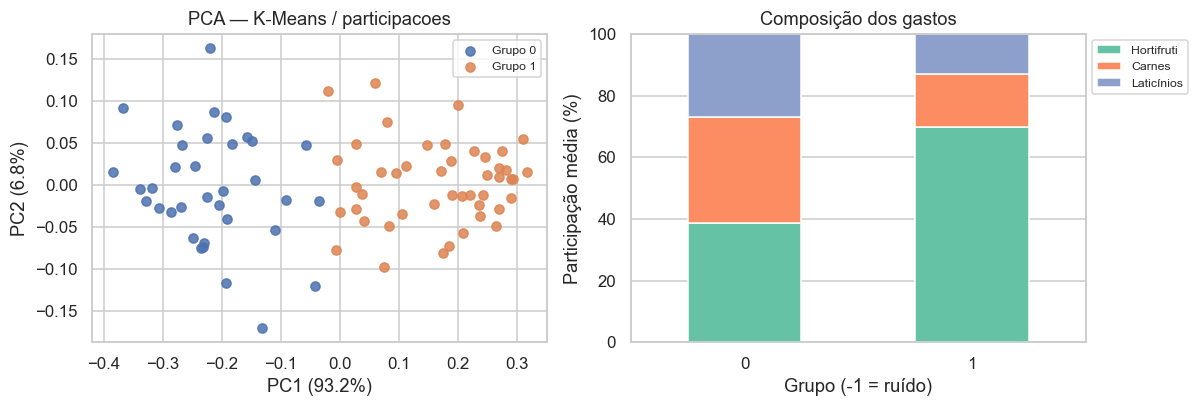

In [ ]:
atribuicoes = df.copy()
todos_perfis, todas_distribuicoes = [], []
perfis_por_par = {}
for _, config in melhores.iterrows():
    rep, alg, identificador = config["representacao"], config["algoritmo"], config["id"]
    rotulos = ajustes[identificador][1]
    dados_grupos = df.assign(grupo=rotulos)
    atribuicoes[f"grupo_{rep}_{alg}"] = rotulos
    grupos = dados_grupos.groupby("grupo", sort=True)
    perfil = grupos.size().rename("n").to_frame()
    perfil["percentual_amostra"] = 100 * perfil["n"] / len(df)
    for c in CATEGORIAS + ["gasto_total"]:
        perfil[f"media_{c}"] = grupos[c].mean()
        perfil[f"mediana_{c}"] = grupos[c].median()
    for c in CATEGORIAS:
        perfil[f"participacao_media_{c}_pct"] = 100 * grupos[f"parcela_{c}"].mean()
    perfil = perfil.reset_index()
    perfil["tipo"] = np.where(perfil["grupo"] == -1, "ruido", "segmento")
    perfil = perfil.assign(representacao=rep, algoritmo=alg, id=identificador)
    perfis_por_par[(rep, alg)] = perfil
    todos_perfis.append(perfil)
    display(Markdown(f"### {rep} — {alg}"))
    display(perfil[["grupo", "tipo", "n", "media_gasto_total"] +
                   [f"participacao_media_{c}_pct" for c in CATEGORIAS]])

    for coluna in ("canal", "pedidos"):
        contagens = pd.crosstab(dados_grupos["grupo"], dados_grupos[coluna])
        percentuais = contagens.div(contagens.sum(axis=1), axis=0) * 100
        for grupo in contagens.index:
            for categoria in contagens.columns:
                todas_distribuicoes.append({"representacao": rep, "algoritmo": alg,
                    "grupo": grupo, "variavel": coluna, "categoria": categoria,
                    "n": int(contagens.loc[grupo, categoria]),
                    "percentual_no_grupo": float(percentuais.loc[grupo, categoria])})

    pca = PCA(n_components=2, svd_solver="full")
    plano = pca.fit_transform(espacos[rep][0])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for grupo in sorted(np.unique(rotulos)):
        mask = rotulos == grupo
        axes[0].scatter(plano[mask, 0], plano[mask, 1], s=36,
                        marker="x" if grupo == -1 else "o",
                        label="Ruído" if grupo == -1 else f"Grupo {grupo}", alpha=0.85)
    axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
                ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
                title=f"PCA — {alg} / {rep}")
    axes[0].legend(fontsize=8)
    valores_perfil = perfil.set_index("grupo")[[f"participacao_media_{c}_pct" for c in CATEGORIAS]]
    valores_perfil.columns = NOMES_CATEGORIAS
    valores_perfil.plot.bar(stacked=True, ax=axes[1], rot=0,
                           color=sns.color_palette("Set2", 3))
    axes[1].set(xlabel="Grupo (-1 = ruído)", ylabel="Participação média (%)", ylim=(0, 100),
                title="Composição dos gastos")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
    fig.tight_layout()
    salvar_figura(fig, f"perfis_{rep}_{alg.lower()}")
    plt.show()
    joblib.dump({"modelo": ajustes[identificador][0],
                 "transformador": espacos[rep][1], "representacao": rep,
                 "variaveis": CATEGORIAS, "parametros": parametros_por_id[identificador],
                 "sha256_dados": sha256_dados},
                SAIDA / "modelos" / f"{rep}_{alg.lower()}.joblib")

perfis = pd.concat(todos_perfis, ignore_index=True) if todos_perfis else pd.DataFrame()
distribuicoes_por_grupo = pd.DataFrame(todas_distribuicoes)
salvar_tabela(perfis, "perfis_segmentos")
salvar_tabela(distribuicoes_por_grupo, "canal_pedidos_por_segmento")
salvar_tabela(atribuicoes, "clientes_segmentados")

## 7. Propostas comerciais para teste

Usamos a configuração K-Means em participações como exemplo comercial
pré-definido. Isso não a declara vencedora dos experimentos. Cada proposta
destaca a categoria com maior diferença de participação média em relação à
amostra. Se não houver configuração elegível, nenhuma proposta é forçada.

A resposta a uma campanha precisaria de um experimento posterior: separar
aleatoriamente clientes elegíveis entre oferta direcionada e comparação,
acompanhar conversão e margem incremental, considerando descontos. A base
atual não tem essas informações. Não inferimos dieta, preferência permanente,
potencial de lucro ou causalidade a partir destes gastos.

In [ ]:
propostas = []
perfil_comercial = perfis_por_par.get(REFERENCIA_COMERCIAL)
participacao_geral = df[COLUNAS_PARCELAS].mean().to_numpy() * 100
if perfil_comercial is not None:
    for _, grupo in perfil_comercial.loc[perfil_comercial["grupo"] >= 0].iterrows():
        participacoes = np.array([grupo[f"participacao_media_{c}_pct"] for c in CATEGORIAS])
        indice = int(np.argmax(participacoes - participacao_geral))
        nome = NOMES_CATEGORIAS[indice]
        propostas.append({
            "grupo": int(grupo["grupo"]), "n": int(grupo["n"]),
            "categoria_em_destaque": nome,
            "participacao_media_pct": float(participacoes[indice]),
            "diferenca_amostra_pp": float(participacoes[indice] - participacao_geral[indice]),
            "proposta_para_teste": f"Testar comunicação de ofertas de {nome.lower()} para este perfil.",
            "validacao_necessaria": "Teste aleatório com grupo de comparação; avaliar conversão e margem incremental.",
        })
acoes_propostas = pd.DataFrame(propostas)
salvar_tabela(acoes_propostas, "acoes_comerciais_propostas")
display(acoes_propostas)

,grupo,n,categoria_em_destaque,participacao_media_pct,diferenca_amostra_pp,proposta_para_teste,validacao_necessaria
0,0,35,Carnes,34.1998,9.7313,Testar comunicação de ofertas de carnes para e...,Teste aleatório com grupo de comparação; avali...
1,1,46,Hortifruti,69.8831,13.4272,Testar comunicação de ofertas de hortifruti pa...,Teste aleatório com grupo de comparação; avali...


## 8. Exportação dos resultados

O pacote final inclui tabelas CSV em UTF-8, figuras PNG/PDF, modelos ajustados,
versões do ambiente, hash da base, parâmetros e um resumo Markdown gerado
com os resultados desta execução. O notebook não publica arquivos no GitHub.

Hierárquico e DBSCAN são usados para descrever a amostra; suas implementações
aqui não fornecem `predict` para novos clientes. K-Means permite essa operação,
usando a mesma transformação do ajuste e informações de gastos equivalentes.
Os modelos `.joblib` só devem ser carregados de fontes confiáveis e com
versões compatíveis; o código permite reconstruí-los sem carregá-los.

In [ ]:
versoes = {pacote.split("==")[0]: version(pacote.split("==")[0])
           for pacote in DEPENDENCIAS.values()}
configuracao = {
    "execucao_utc": EXECUCAO, "semente": SEMENTE,
    "arquivo": caminho_dados.name, "sha256_dados": sha256_dados,
    "n_clientes": len(df), "python": platform.python_version(), "versoes": versoes,
    "k_testados": K_TESTADOS, "n_init_kmeans": N_INIT_KMEANS,
    "min_samples_dbscan": MIN_SAMPLES_DBSCAN, "quantis_eps": QUANTIS_EPS,
    "multiplicadores_eps": MULTIPLICADORES_EPS,
    "min_tamanho_grupo": MIN_TAMANHO_GRUPO, "min_cobertura": MIN_COBERTURA,
    "criterio_selecao": "cobertura * silhueta - (1 - cobertura)",
    "repeticoes_estabilidade": REPETICOES_ESTABILIDADE,
    "fracao_subamostra": FRACAO_SUBAMOSTRA,
    "n_subamostra": n_subamostra,
    "referencia_comercial": REFERENCIA_COMERCIAL,
    "n_configuracoes": len(resultados),
    "n_casos_iqr": int(mascara_atipicos.sum()),
    "configuracoes_selecionadas": melhores["id"].tolist(),
}
(SAIDA / "configuracao.json").write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2), encoding="utf-8")
(SAIDA / "requirements-execucao.txt").write_text(
    "\n".join(f"{pacote}=={versao}" for pacote, versao in versoes.items()) + "\n",
    encoding="utf-8")

linhas = ["# Resultados da execução", "",
    f"Base: {len(df)} clientes. SHA-256: `{sha256_dados}`.", "",
    f"Configurações avaliadas: {len(resultados)}. Casos IQR mantidos: {mascara_atipicos.sum()}.", "",
    "## Configurações selecionadas por algoritmo e representação", "",
    "| Representação | Algoritmo | Parâmetros | Grupos | Cobertura | Silhueta | ARI mediano | Repetições elegíveis |",
    "| --- | --- | --- | ---: | ---: | ---: | ---: | ---: |"]
for _, r in comparacao.iterrows():
    linhas.append(f"| {r['representacao']} | {r['algoritmo']} | `{r['parametros']}` | "
                  f"{r['n_grupos']} | {r['cobertura']:.1%} | {r['silhueta']:.3f} | "
                  f"{r['ari_mediano']:.3f} | {r['fracao_repeticoes_elegiveis']:.1%} |")
for rep in REPRESENTACOES:
    for alg in ALGORITMOS:
        if (rep, alg) not in pares_encontrados:
            linhas.append(f"\nSem configuração elegível: **{rep} / {alg}**.")
linhas += ["", "## Interpretação e limites", "",
    "- Não há rótulos externos: silhueta e ARI não são acurácia nem validação de perfis reais.",
    "- A busca e a avaliação interna utilizam a mesma amostra; os melhores valores são exploratórios e podem ser otimistas.",
    "- A estabilidade é condicional aos parâmetros escolhidos, com transformação reajustada nas subamostras.",
    "- Observe ARI dos agrupados, cobertura comum e fração de repetições elegíveis, especialmente no DBSCAN.",
    "- Não compare representações apenas pelo valor de silhueta: elas usam geometrias distintas.",
    "- Silhueta favorece certos formatos de grupos; não deve ser o único critério comercial.",
    "- Os 81 clientes e a origem amostral desconhecida limitam generalizações.",
    "- Não há medidas de campanha, margem, demanda futura ou causalidade.",
    "- Números de segmentos são arbitrários; não equivalem entre modelos.",
    "", "## Arquivos para o artigo", "",
    "- `tabelas/comparacao_com_estabilidade.csv`: métricas principais e estabilidade.",
    "- `tabelas/perfis_segmentos.csv`: descrição dos segmentos.",
    "- `tabelas/canal_pedidos_por_segmento.csv`: distribuição por canal e pedidos.",
    "- `tabelas/sensibilidade_atipicos.csv`: controle de sensibilidade.",
    "- `tabelas/acoes_comerciais_propostas.csv`: sugestões ainda não testadas.",
    "- `figuras/`: gráficos em PNG e PDF.", ""]
(SAIDA / "resumo_resultados.md").write_text("\n".join(linhas), encoding="utf-8")
zip_resultados = Path(shutil.make_archive(str(SAIDA), "zip", root_dir=SAIDA))
print("Resultados exportados:", SAIDA.as_posix())
print("ZIP:", zip_resultados.as_posix())
display(Markdown("\n".join(linhas)))

Resultados exportados: resultados/execucao_20261112T015226_452281Z
ZIP: C:/Users/Abraa/Downloads/segmentacao-supermercado/resultados/execucao_20261112T015226_452281Z.zip


# Resultados da execução

Base: 81 clientes. SHA-256: `d9413c2731075fb06f13f6e8e20d1d3e8af528667ec3c98d6fccbfb878aa2ade`.

Configurações avaliadas: 110. Casos IQR mantidos: 4.

## Configurações selecionadas por algoritmo e representação

| Representação | Algoritmo | Parâmetros | Grupos | Cobertura | Silhueta | ARI mediano | Repetições elegíveis |
| --- | --- | --- | ---: | ---: | ---: | ---: | ---: |
| absolutos | DBSCAN | `{"eps": 0.6358384737654358, "min_samples": 3}` | 3 | 82.7% | 0.245 | 0.654 | 3.3% |
| absolutos | Hierarquico | `{"k": 2}` | 2 | 100.0% | 0.408 | 0.178 | 100.0% |
| absolutos | K-Means | `{"k": 2}` | 2 | 100.0% | 0.440 | 1.000 | 100.0% |
| participacoes | DBSCAN | `{"eps": 0.08243308765059705, "min_samples": 8}` | 2 | 97.5% | 0.599 | 0.896 | 96.7% |
| participacoes | Hierarquico | `{"k": 2}` | 2 | 100.0% | 0.594 | 0.906 | 100.0% |
| participacoes | K-Means | `{"k": 2}` | 2 | 100.0% | 0.611 | 1.000 | 100.0% |

## Interpretação e limites

- Não há rótulos externos: silhueta e ARI não são acurácia nem validação de perfis reais.
- A busca e a avaliação interna utilizam a mesma amostra; os melhores valores são exploratórios e podem ser otimistas.
- A estabilidade é condicional aos parâmetros escolhidos, com transformação reajustada nas subamostras.
- Observe ARI dos agrupados, cobertura comum e fração de repetições elegíveis, especialmente no DBSCAN.
- Não compare representações apenas pelo valor de silhueta: elas usam geometrias distintas.
- Silhueta favorece certos formatos de grupos; não deve ser o único critério comercial.
- Os 81 clientes e a origem amostral desconhecida limitam generalizações.
- Não há medidas de campanha, margem, demanda futura ou causalidade.
- Números de segmentos são arbitrários; não equivalem entre modelos.

## Arquivos para o artigo

- `tabelas/comparacao_com_estabilidade.csv`: métricas principais e estabilidade.
- `tabelas/perfis_segmentos.csv`: descrição dos segmentos.
- `tabelas/canal_pedidos_por_segmento.csv`: distribuição por canal e pedidos.
- `tabelas/sensibilidade_atipicos.csv`: controle de sensibilidade.
- `tabelas/acoes_comerciais_propostas.csv`: sugestões ainda não testadas.
- `figuras/`: gráficos em PNG e PDF.


In [ ]:
# No Colab, o ZIP também pode ser baixado pelo painel de arquivos à esquerda.
if BAIXAR_ZIP_NO_COLAB:
    try:
        from google.colab import files
    except ImportError:
        print("Execução local: o ZIP já está na pasta resultados/.")
    else:
        files.download(str(zip_resultados))